# EDUCATION PROJECT

### Research question: Can socioeconomic factors predict a school's average ACT score? We also investigate whether adding charter school status improves predictions.

This notebook continues the work in the separate data-preparation notebook, which loads and joins the original EdGap data and the Common Core of Data (CCD) school information. The prepared file is education_clean.csv. We use exploratory plots and simple linear regression to answer the question. Relationships in this analysis are associations, not evidence of causation.

# Import libraries

In [5]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Load clean data

In [7]:
df = pd.read_csv("/Users/linhchung/Documents/GitHub/Education-Project/data/education_clean.csv")

In [8]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No


# Exploratory data analysis

## Examine distributions and relationships

### Plot the correlation matrix of the numerical variables in the data to explore relationships between the variables.

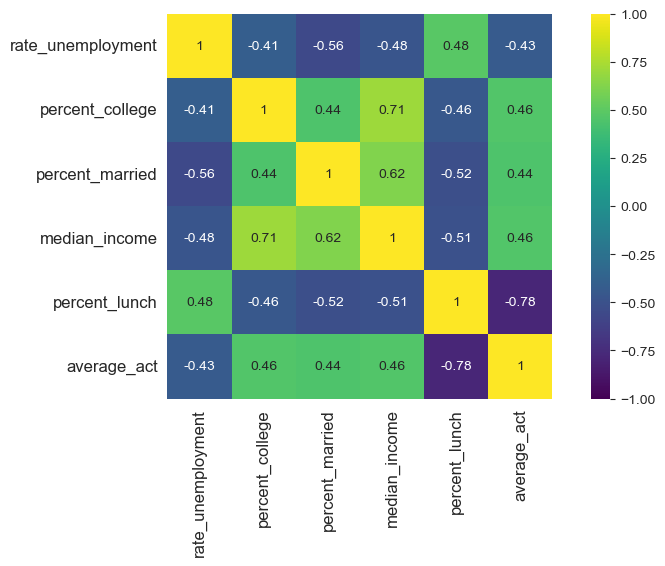

In [12]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state', 
    'charter'
]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

We will look at the correlation between average_act and the predictor variables, as well as the correlation among those predictor variables.

### Make pair plots to explore relationships between the variables.

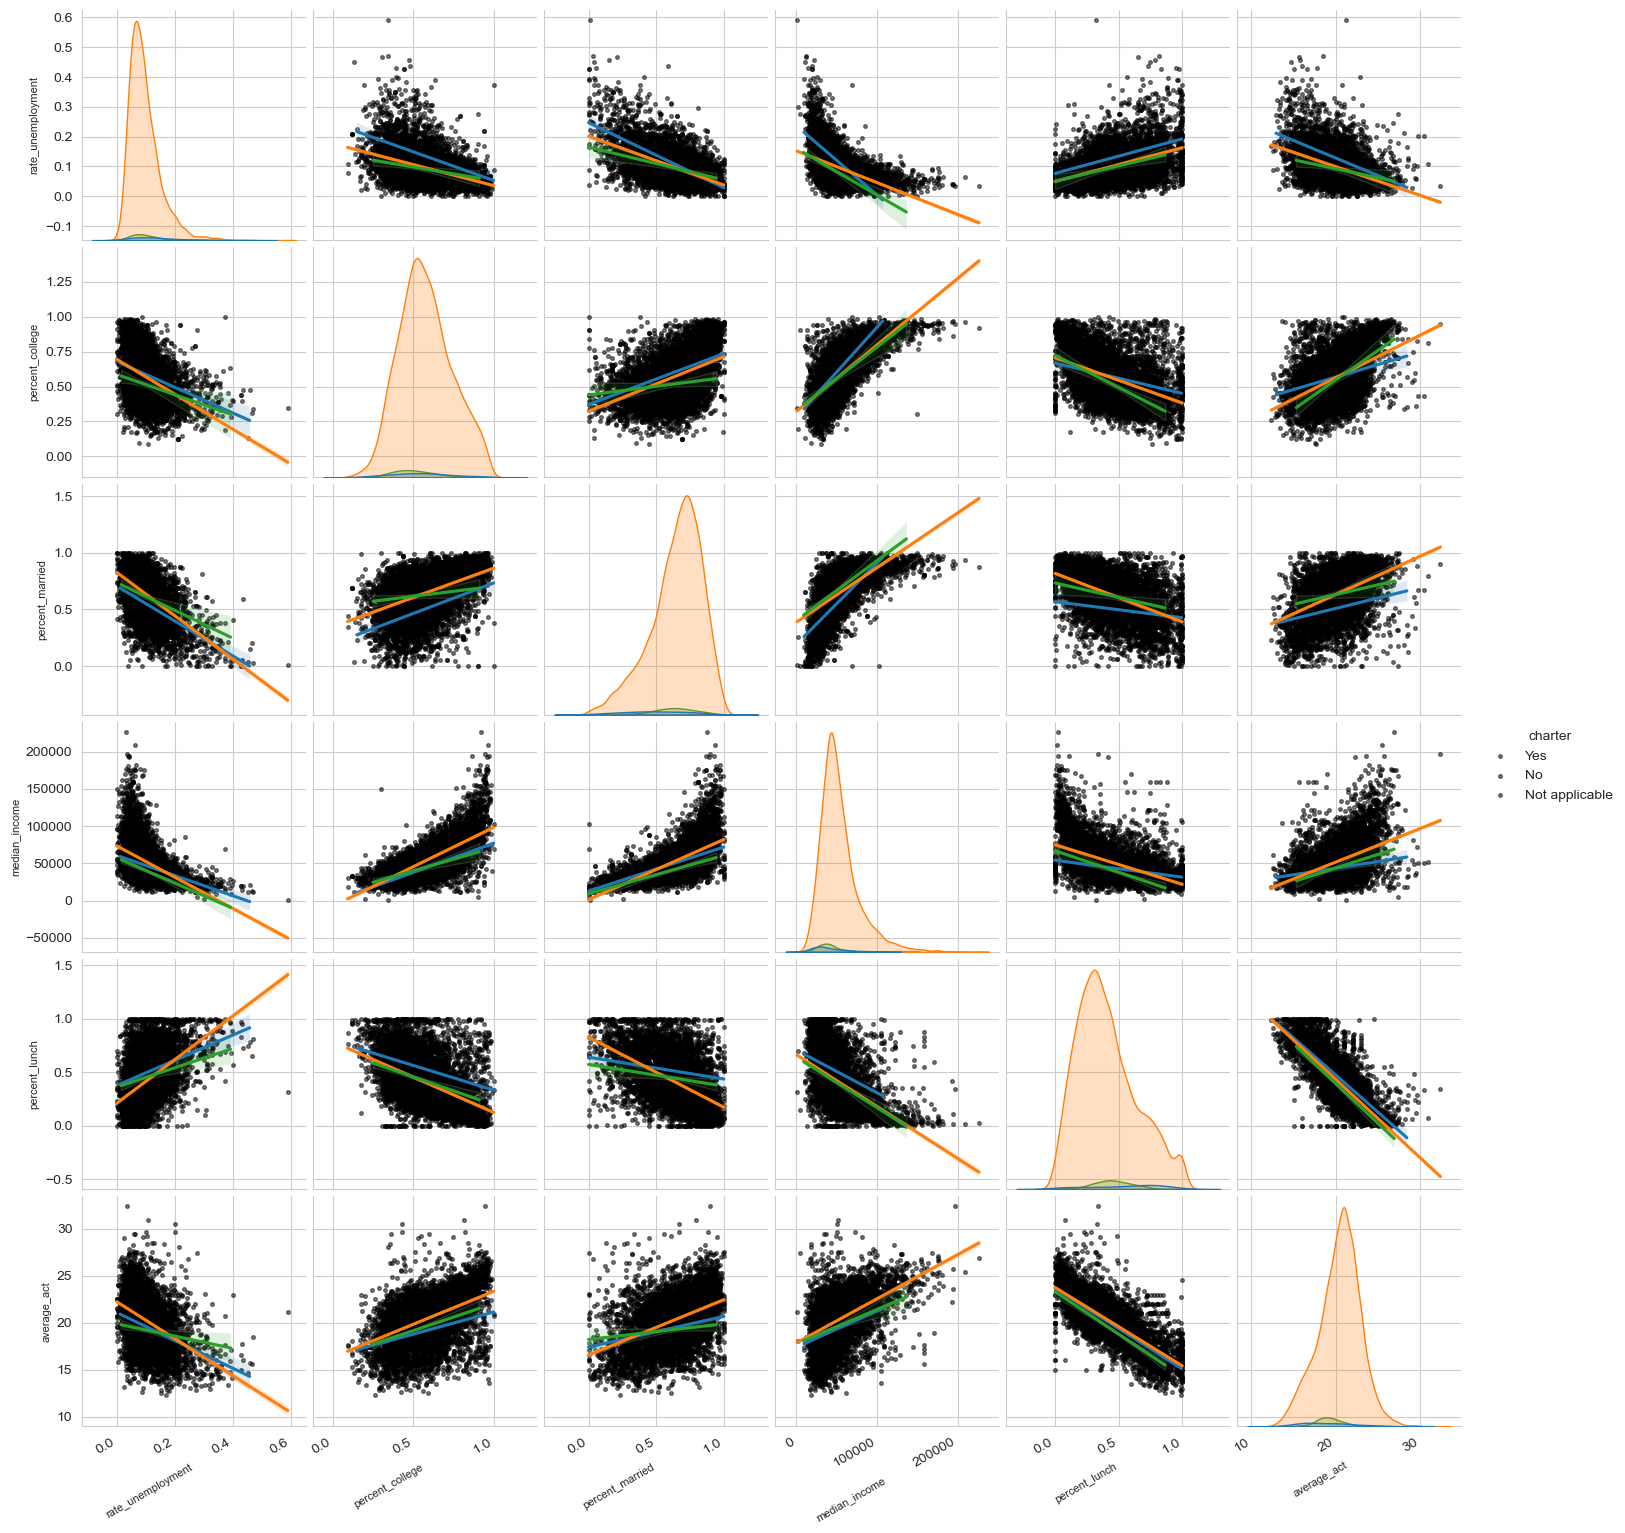

In [15]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    hue = 'charter',
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

### Identify outliers

We can use the interquartile range to identify outliers. This is also evident in boxplots of the data. Median income is on a very different scale than the other predictors, so we will make two plots to explore the data.

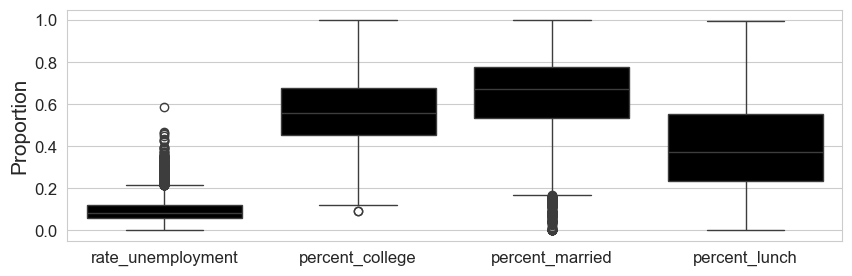

In [18]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

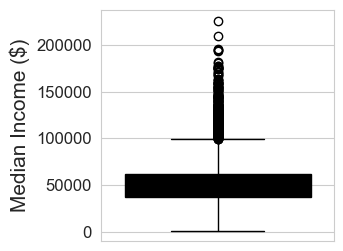

In [19]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

## Summary
1. The numerical predictors are related to average_act. The relationships appear roughly linear.
2. The numerical predictors are correlated with each other, suggesting that not all predictors will be necessary.
3. Some variables have skewed distributions, suggesting that transformations of input variables might be useful.
4. There are outliers in rate_unemployment, percent_college, percent_married and median_income. None of these are obviously incorrect values; they likely reflect skewed distributions. We may consider applying something like a log transformation to these predictors as we explore different models.
5. The relationships are similar across charter and non-charter schools, but might be significantly different.

## Modeling

### Single input models

Fit and assess models predicting the average ACT score from each of the input variables. You might try polynomial linear regression models, as appropriate. 

### Median Income

#### Plot the regression linear and scatter plot

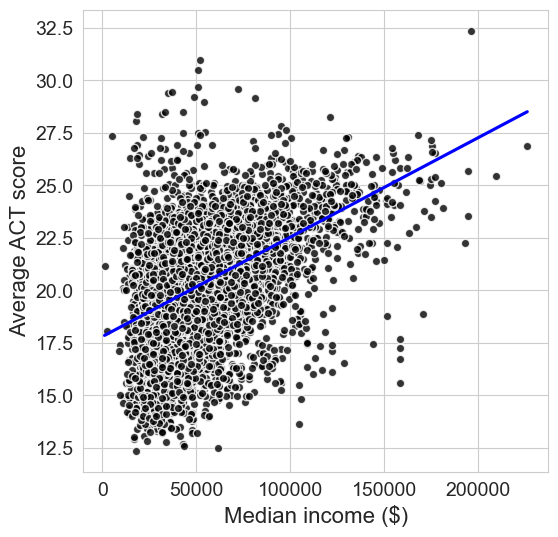

In [26]:
plt.figure(figsize=(6,6))

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})
# Add axis labels
plt.xlabel('Median income ($)', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

#Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

Fit the simple linear regression model

In [28]:
model_median_income = smf.ols(formula='average_act ~ median_income', data=df).fit()

In [29]:
print(model_median_income.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.211
Model:                            OLS   Adj. R-squared:                  0.211
Method:                 Least Squares   F-statistic:                     1934.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:13:28   Log-Likelihood:                -16043.
No. Observations:                7227   AIC:                         3.209e+04
Df Residuals:                    7225   BIC:                         3.210e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        17.8026      0.063    284.794

#### Numerical assesment of fit accuracy

##### Compute the R-squared

In [32]:
model_median_income.rsquared

0.21118648979300925

##### Compute the RMSE

In [34]:
y_hat = model_median_income.predict()

In [35]:
np.sqrt(mean_squared_error(df['average_act'], y_hat)).round(3)

2.228

##### Compute the mean absolute error

In [37]:
mean_absolute_error(df['average_act'], y_hat)

1.7129386980688623

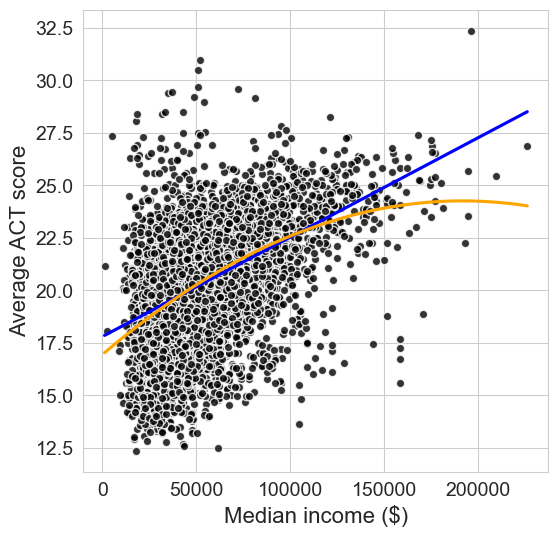

In [38]:
plt.figure(figsize=(6,6))

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            color='blue',
            ci=False,
            scatter_kws={'color': 'black', 'edgecolors': 'white', 'linewidths': 1})

sns.regplot(data=df,
            x='median_income',
            y='average_act',
            order=2,
            color='orange',
            ci=False,
            scatter=False)

# Add axis labels
plt.xlabel('Median income ($)', fontsize=16)
plt.ylabel('Average ACT score', fontsize=16)

#Increase the fontsize of the tick labels
plt.tick_params(labelsize=14)

plt.show()

##### Fit a quadratic linear regression model

In [40]:
model_median_income2 = smf.ols(
    formula='average_act ~ median_income + I(median_income**2)',
    data=df).fit()

##### Display the summary

In [42]:
print(model_median_income2.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.219
Model:                            OLS   Adj. R-squared:                  0.219
Method:                 Least Squares   F-statistic:                     1013.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:13:29   Log-Likelihood:                -16007.
No. Observations:                7227   AIC:                         3.202e+04
Df Residuals:                    7224   BIC:                         3.204e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept                16.94

##### Assess the model significance

In [44]:
model_median_income2.pvalues

Intercept                0.000000e+00
median_income            2.631899e-99
I(median_income ** 2)    1.395848e-17
dtype: float64

In [45]:
anova_lm(model_median_income, model_median_income2)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,7225.0,35865.012794,0.0,NaN,NaN,NaN
1,7224.0,35505.105960,1.0,359.906834,73.227974,1.395848e-17


##### Assess the model accuracy

Compute the mean absolute error

In [53]:
mean_absolute_error(df['average_act'], model_median_income2.predict())

1.6972389257904303

In [55]:
mean_absolute_error(df['average_act'], model_median_income.predict())

1.7129386980688623

### Additional Predictor

In [60]:
model_charter = smf.ols(
    formula='average_act ~ rate_unemployment + percent_college + percent_married + median_income + percent_lunch + C(charter)',
    data=df
).fit()

print(model_charter.summary())

                            OLS Regression Results                            
Dep. Variable:            average_act   R-squared:                       0.630
Model:                            OLS   Adj. R-squared:                  0.630
Method:                 Least Squares   F-statistic:                     1757.
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        02:18:14   Log-Likelihood:                -13307.
No. Observations:                7227   AIC:                         2.663e+04
Df Residuals:                    7219   BIC:                         2.669e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                   coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

## Conclusion

The purpose of this project was to investigate whether socioeconomic factors can predict average ACT scores among U.S. high schools. The research question can be answered using the available data because average ACT scores and several socioeconomic variables are included in the dataset.

The exploratory analysis showed that socioeconomic factors are associated with average ACT scores. Among the individual predictors, the percentage of students receiving free or reduced-price lunch had the strongest correlation with ACT scores (r = -0.785). Median household income also had a positive correlation (r = 0.460), but its relationship was weaker.

One possible explanation is that lunch participation reflects the economic circumstances of students attending a school more directly than census tract median income, which describes the surrounding community.

The earlier multiple regression analysis achieved a test R-squared value of 0.615, indicating that the socioeconomic predictors explained approximately 61.5% of the variation in ACT scores in the test dataset, relative to the test-set mean. However, the model did not explain all differences in school performance.

There were also limitations in the data. Some observations contained missing or invalid values, which required cleaning and imputation. In addition, socioeconomic characteristics measured at the census tract level may not accurately represent the backgrounds of individual students. Differences in testing participation across schools and states may also affect comparisons.

Overall, the analysis suggests that socioeconomic factors can help predict average ACT scores, but these relationships do not establish causation. Additional information about school resources, student characteristics, and educational opportunities could improve future analyses.